In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

SEED = 42
df = pd.read_csv("../data/shots_clean.csv")

# one-hot encode text categories: e.g. body part -> Head / Left Foot / Right Foot / Other as 0/1 columns
cats = ["shot_body_part", "shot_type", "play_pattern"]
df = pd.get_dummies(df, columns=cats, dtype=float)

num_cols = ["distance", "angle"]
cat_cols = [c for c in df.columns if c.startswith(tuple(f"{c}_" for c in cats))]
FEATURES = num_cols + ["under_pressure", "shot_first_time"] + cat_cols
print(len(FEATURES), "features:", FEATURES)

20 features: ['distance', 'angle', 'under_pressure', 'shot_first_time', 'shot_body_part_Head', 'shot_body_part_Left Foot', 'shot_body_part_Other', 'shot_body_part_Right Foot', 'shot_type_Corner', 'shot_type_Free Kick', 'shot_type_Open Play', 'play_pattern_From Corner', 'play_pattern_From Counter', 'play_pattern_From Free Kick', 'play_pattern_From Goal Kick', 'play_pattern_From Keeper', 'play_pattern_From Kick Off', 'play_pattern_From Throw In', 'play_pattern_Other', 'play_pattern_Regular Play']


In [2]:
# first carve off 15% of matches as TEST, then split the rest into TRAIN / VALIDATION
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tv_idx, te_idx = next(gss.split(df, groups=df["match_id"]))
trainval, test = df.iloc[tv_idx], df.iloc[te_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
tr_idx, va_idx = next(gss2.split(trainval, groups=trainval["match_id"]))
train, val = trainval.iloc[tr_idx], trainval.iloc[va_idx]

# leakage check: no match appears in two sets
assert not set(train.match_id) & set(val.match_id)
assert not set(train.match_id) & set(test.match_id)
assert not set(val.match_id) & set(test.match_id)

# standardize numeric features using TRAINING statistics only
mu, sd = train[num_cols].mean(), train[num_cols].std()
def prep(d):
    X = d[FEATURES].copy()
    X[num_cols] = (X[num_cols] - mu) / sd
    return X.values.astype(float), d["goal"].values

Xtr, ytr = prep(train)
Xva, yva = prep(val)
Xte, yte = prep(test)
for name, y in [("train", ytr), ("val", yva), ("test", yte)]:
    print(f"{name}: {len(y)} shots, goal rate {y.mean():.3f}")

train: 46175 shots, goal rate 0.099
val: 9849 shots, goal rate 0.101
test: 9798 shots, goal rate 0.110


In [3]:
def evaluate(name, y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return {"model": name, "log_loss": log_loss(y, p),
            "brier": brier_score_loss(y, p), "roc_auc": roc_auc_score(y, p)}

results = []
# Baseline 0: every shot gets the training goal rate
results.append(evaluate("Constant", yva, np.full(len(yva), ytr.mean())))

# Baseline 1: logistic regression on distance + angle only
base = LogisticRegression().fit(Xtr[:, :2], ytr)
results.append(evaluate("Logistic (dist+angle)", yva, base.predict_proba(Xva[:, :2])[:, 1]))

# Benchmark: StatsBomb's professional xG
results.append(evaluate("StatsBomb xG", yva, val["shot_statsbomb_xg"].values))
pd.DataFrame(results)

,model,log_loss,brier,roc_auc
0,Constant,0.327569,0.090903,0.500000
1,Logistic (dist+angle),0.287705,0.082252,0.753333
2,StatsBomb xG,0.259881,0.073823,0.812846


In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def train_neuron(X, y, lr=0.5, l2=0.0, epochs=1000, Xv=None, yv=None, seed=SEED):
    rng = np.random.default_rng(seed)
    w = rng.normal(0, 0.01, X.shape[1])   # small random starting weights
    b = 0.0
    history = []
    for ep in range(epochs):
        p = sigmoid(X @ w + b)            # forward pass: predicted goal probability
        err = p - y                       # gradient of cross-entropy w.r.t. z simplifies to (p - y)
        grad_w = X.T @ err / len(y) + l2 * w
        grad_b = err.mean()
        w -= lr * grad_w                  # steepest descent step
        b -= lr * grad_b
        if Xv is not None and ep % 10 == 0:
            history.append((ep, log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)),
                                log_loss(yv, np.clip(sigmoid(Xv @ w + b), 1e-7, 1 - 1e-7))))
    return w, b, history

     lr      l2 model  log_loss     brier   roc_auc
8   0.5  0.0000     A  0.273059  0.078080  0.786389
9   0.5  0.0001     A  0.273075  0.078084  0.786467
12  1.0  0.0000     A  0.273082  0.078095  0.786305
13  1.0  0.0001     A  0.273095  0.078098  0.786392
10  0.5  0.0010     A  0.273298  0.078141  0.787017


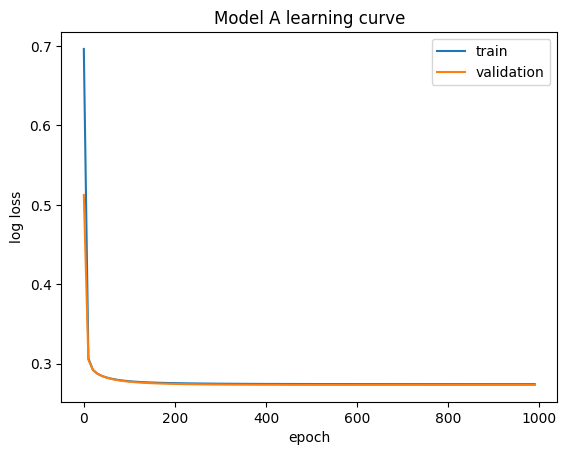

shot_body_part_Head           -1.116856
shot_type_Open Play           -1.075289
distance                      -0.925534
play_pattern_From Corner      -0.729793
play_pattern_From Free Kick   -0.260175
under_pressure                -0.259120
play_pattern_From Throw In    -0.188930
shot_body_part_Other          -0.166690
shot_first_time               -0.133521
shot_type_Free Kick           -0.110371
play_pattern_From Kick Off    -0.105154
play_pattern_From Goal Kick   -0.086244
play_pattern_Regular Play     -0.084917
play_pattern_From Keeper      -0.052281
play_pattern_Other             0.017318
shot_type_Corner               0.040468
shot_body_part_Left Foot       0.041127
shot_body_part_Right Foot      0.062714
play_pattern_From Counter      0.363066
angle                          0.445657
dtype: float64


,model,log_loss,brier,roc_auc
0,Constant,0.327569,0.090903,0.500000
1,Logistic (dist+angle),0.287705,0.082252,0.753333
2,StatsBomb xG,0.259881,0.073823,0.812846
3,Model A (neuron),0.273059,0.078080,0.786389


In [5]:
grid = []
for lr in [0.05, 0.1, 0.5, 1.0]:
    for l2 in [0, 1e-4, 1e-3, 1e-2]:
        w, b, _ = train_neuron(Xtr, ytr, lr=lr, l2=l2)
        p = sigmoid(Xva @ w + b)
        grid.append({"lr": lr, "l2": l2, **evaluate("A", yva, p)})
grid = pd.DataFrame(grid).sort_values("log_loss")
print(grid.head())

best = grid.iloc[0]
w, b, hist = train_neuron(Xtr, ytr, lr=best.lr, l2=best.l2, Xv=Xva, yv=yva)
results.append(evaluate("Model A (neuron)", yva, sigmoid(Xva @ w + b)))

h = np.array(hist)
plt.plot(h[:, 0], h[:, 1], label="train"); plt.plot(h[:, 0], h[:, 2], label="validation")
plt.xlabel("epoch"); plt.ylabel("log loss"); plt.title("Model A learning curve"); plt.legend()
plt.savefig("../figures/modelA_learning_curve.png", dpi=150); plt.show()

print(pd.Series(w, index=FEATURES).sort_values())   # feature weights = interpretability
pd.DataFrame(results)

In [6]:
import warnings
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")   # hides convergence warnings while tuning

grid_b = []
for hidden in [(16,), (32,), (32, 16)]:
    for alpha in [1e-4, 1e-3, 1e-2]:
        mlp = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha,
                            learning_rate_init=1e-3, max_iter=200, random_state=SEED)
        mlp.fit(Xtr, ytr)
        p = mlp.predict_proba(Xva)[:, 1]
        grid_b.append({"hidden": hidden, "alpha": alpha, **evaluate("B", yva, p)})
        print(hidden, alpha, "done")

grid_b = pd.DataFrame(grid_b).sort_values("log_loss")
print(grid_b.head())

(16,) 0.0001 done
(16,) 0.001 done
(16,) 0.01 done
(32,) 0.0001 done
(32,) 0.001 done
(32,) 0.01 done
(32, 16) 0.0001 done
(32, 16) 0.001 done
(32, 16) 0.01 done
  hidden   alpha model  log_loss     brier   roc_auc
5  (32,)  0.0100     B  0.272286  0.078009  0.789163
4  (32,)  0.0010     B  0.272419  0.078036  0.788538
2  (16,)  0.0100     B  0.272509  0.078183  0.788895
1  (16,)  0.0010     B  0.272535  0.078206  0.789434
3  (32,)  0.0001     B  0.272540  0.078071  0.788379


In [7]:
best_b = grid_b.iloc[0]
mlp = MLPClassifier(hidden_layer_sizes=best_b.hidden, alpha=best_b.alpha,
                    learning_rate_init=1e-3, max_iter=200, random_state=SEED).fit(Xtr, ytr)
results.append(evaluate("Model B (neural net)", yva, mlp.predict_proba(Xva)[:, 1]))
pd.DataFrame(results)

,model,log_loss,brier,roc_auc
0,Constant,0.327569,0.090903,0.500000
1,Logistic (dist+angle),0.287705,0.082252,0.753333
2,StatsBomb xG,0.259881,0.073823,0.812846
3,Model A (neuron),0.273059,0.078080,0.786389
4,Model B (neural net),0.272286,0.078009,0.789163


In [8]:
pA = sigmoid(Xte @ w + b)
pB = mlp.predict_proba(Xte)[:, 1]
preds = {
    "Constant": np.full(len(yte), ytr.mean()),
    "Logistic (dist+angle)": base.predict_proba(Xte[:, :2])[:, 1],
    "Model A (neuron)": pA,
    "Model B (neural net)": pB,
    "StatsBomb xG": test["shot_statsbomb_xg"].values,
}

# bootstrap: resample the test shots 1000 times to see how much the AUC wobbles
rng = np.random.default_rng(SEED)
boot = [rng.integers(0, len(yte), len(yte)) for _ in range(1000)]

rows = []
for name, p in preds.items():
    r = evaluate(name, yte, p)
    if name != "Constant":
        aucs = [roc_auc_score(yte[i], p[i]) for i in boot]
        r["auc_95ci"] = f"[{np.percentile(aucs, 2.5):.3f}, {np.percentile(aucs, 97.5):.3f}]"
    rows.append(r)
final = pd.DataFrame(rows)
final.to_csv("../figures/test_results.csv", index=False)

# is B really better than A? look at the difference on the SAME resamples
diff = [roc_auc_score(yte[i], pB[i]) - roc_auc_score(yte[i], pA[i]) for i in boot]
print(f"AUC(B) - AUC(A): 95% CI [{np.percentile(diff, 2.5):.4f}, {np.percentile(diff, 97.5):.4f}]")
final

AUC(B) - AUC(A): 95% CI [-0.0011, 0.0056]


,model,log_loss,brier,roc_auc,auc_95ci
0,Constant,0.347848,0.098276,0.500000,NaN
1,Logistic (dist+angle),0.308877,0.089623,0.743984,"[0.729, 0.759]"
2,Model A (neuron),0.292325,0.084915,0.781398,"[0.766, 0.795]"
3,Model B (neural net),0.290962,0.084601,0.783439,"[0.768, 0.797]"
4,StatsBomb xG,0.275436,0.079961,0.816866,"[0.802, 0.831]"


In [9]:
seed_rows = []
for s in range(5):
    wA, bA, _ = train_neuron(Xtr, ytr, lr=best.lr, l2=best.l2, seed=s)
    mB = MLPClassifier(hidden_layer_sizes=best_b.hidden, alpha=best_b.alpha,
                       learning_rate_init=1e-3, max_iter=200, random_state=s).fit(Xtr, ytr)
    seed_rows.append({"seed": s,
                      "A_auc": roc_auc_score(yte, sigmoid(Xte @ wA + bA)),
                      "B_auc": roc_auc_score(yte, mB.predict_proba(Xte)[:, 1])})
seeds = pd.DataFrame(seed_rows)
print(seeds)
print(seeds[["A_auc", "B_auc"]].agg(["mean", "std"]))

   seed     A_auc     B_auc
0     0  0.781406  0.783624
1     1  0.781412  0.782397
2     2  0.781419  0.783837
3     3  0.781409  0.782936
4     4  0.781386  0.783041
         A_auc     B_auc
mean  0.781406  0.783167
std   0.000012  0.000574


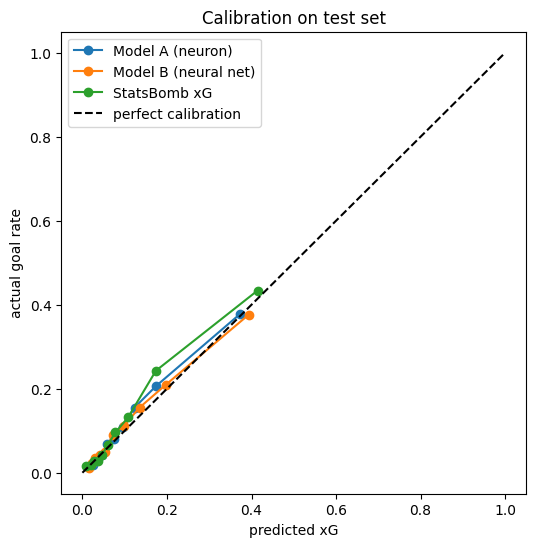

In [10]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(6, 6))
for name in ["Model A (neuron)", "Model B (neural net)", "StatsBomb xG"]:
    frac_goals, mean_pred = calibration_curve(yte, preds[name], n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_goals, marker="o", label=name)
plt.plot([0, 1], [0, 1], "k--", label="perfect calibration")
plt.xlabel("predicted xG"); plt.ylabel("actual goal rate")
plt.title("Calibration on test set"); plt.legend()
plt.savefig("../figures/calibration.png", dpi=150); plt.show()

In [11]:
# ABLATION (on validation): retrain Model A with one feature group removed at a time
groups = {
    "body part": [c for c in FEATURES if c.startswith("shot_body_part_")],
    "shot type": [c for c in FEATURES if c.startswith("shot_type_")],
    "play pattern": [c for c in FEATURES if c.startswith("play_pattern_")],
    "pressure + first time": ["under_pressure", "shot_first_time"],
}
abl = [{"removed": "nothing (full model)", **evaluate("A", yva, sigmoid(Xva @ w + b))}]
for gname, drop in groups.items():
    keep = [i for i, c in enumerate(FEATURES) if c not in drop]
    wA, bA, _ = train_neuron(Xtr[:, keep], ytr, lr=best.lr, l2=best.l2)
    abl.append({"removed": gname, **evaluate("A", yva, sigmoid(Xva[:, keep] @ wA + bA))})
print(pd.DataFrame(abl)[["removed", "log_loss", "roc_auc"]])

# GENERALIZATION: Model B's test AUC per competition (only competitions with 300+ test shots)
t = test.assign(pB=pB, pSB=test["shot_statsbomb_xg"])
by_comp = t.groupby("competition").filter(lambda d: len(d) >= 300).groupby("competition").apply(
    lambda d: pd.Series({"shots": len(d),
                         "model_B_auc": roc_auc_score(d["goal"], d["pB"]),
                         "statsbomb_auc": roc_auc_score(d["goal"], d["pSB"])}))
by_comp

                 removed  log_loss   roc_auc
0   nothing (full model)  0.273059  0.786389
1              body part  0.277327  0.776397
2              shot type  0.274072  0.783667
3           play pattern  0.275598  0.782082
4  pressure + first time  0.273544  0.785741


,shots,model_B_auc,statsbomb_auc
competition,,,
FIFA World Cup,459.0,0.785515,0.812103
Indian Super league,411.0,0.756193,0.814095
La Liga,3218.0,0.777079,0.804359
Ligue 1,1783.0,0.794729,0.827992
Premier League,1412.0,0.774483,0.820507
Serie A,1541.0,0.794191,0.824845
UEFA Euro,487.0,0.794319,0.838436
